In [24]:
import pandas as pd
import numpy as np
import librosa
import os, time, inspect, glob, random, itertools
import matplotlib.pyplot as plt

In [25]:
SEED = 42
random.seed(SEED); np.random.seed(SEED); os.environ['PYTHONHASHSEED'] = str(SEED)
path = 'data/schematics-2026'
metas = pd.read_csv(f'{path}/train/metadata.csv')
metas

,file_id,audio_path,label,source_group
0,313fef340a5c0be86a6c3ec29bb0fc5b684accd321f994...,train/audio/313fef340a5c0be86a6c3ec29bb0fc5b68...,Bondol Jawa,d20bbb9d3f16cea2e0988846afe752fa7233d9de8cffd7...
1,9f0d58ab5eb8bdad788915ba9053c9a23b2709461ee290...,train/audio/9f0d58ab5eb8bdad788915ba9053c9a23b...,Bondol Jawa,100f6ca56523c6b10f0da48fca4a3100f7e2fad1a2c238...
2,f18d5438129a6c8fabe09f8d108c44b0fa40880cf0ffcb...,train/audio/f18d5438129a6c8fabe09f8d108c44b0fa...,Kutilang,81b28e5fe98ace507d968e64f7cf87d7c4af112b8d3d19...
3,ec4ea61e4451227b2ee1e4046296b515e4f58761ea4097...,train/audio/ec4ea61e4451227b2ee1e4046296b515e4...,Bondol Jawa,d20bbb9d3f16cea2e0988846afe752fa7233d9de8cffd7...
4,d0bd6e1839642188508060a7bb5c29c1a8251ada1a48f0...,train/audio/d0bd6e1839642188508060a7bb5c29c1a8...,Kutilang,0d9c30be6d4b5d92c8384b9e5fd3cf908e4b8a965c68a9...
...,...,...,...,...
1821,aa83eca4af347ade7cedd5409c06b8878c062e94b4adc9...,train/audio/aa83eca4af347ade7cedd5409c06b8878c...,Bondol Jawa,d20bbb9d3f16cea2e0988846afe752fa7233d9de8cffd7...
1822,7212eee35423e64bdcec85d1418d5d68a6ca11fc45d2fb...,train/audio/7212eee35423e64bdcec85d1418d5d68a6...,Kutilang,81b28e5fe98ace507d968e64f7cf87d7c4af112b8d3d19...
1823,18a6da4c3e45e6a6cf3f3c51c99b5028902663d537490a...,train/audio/18a6da4c3e45e6a6cf3f3c51c99b502890...,Bondol Jawa,c04cd5b92abf641020d05d3c6493551c25788d00c0cf3d...
1824,bff6da68be0e6f57c7962d267f1854a54b3fba3ab75cbf...,train/audio/bff6da68be0e6f57c7962d267f1854a54b...,Bondol Jawa,90eace95f77b860fc6f9a3ec8c870c251172f7292ca8f6...


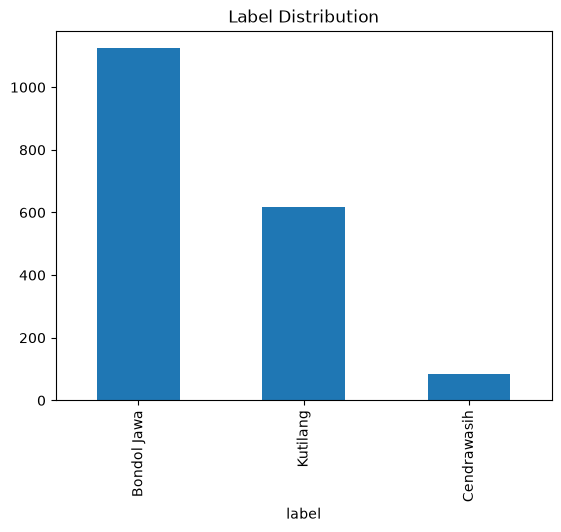

In [26]:
metas['label'].value_counts().plot(kind='bar', title='Label Distribution')
plt.show()

In [27]:
metas.info()

<class 'pandas.DataFrame'>
RangeIndex: 1826 entries, 0 to 1825
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   file_id       1826 non-null   str  
 1   audio_path    1826 non-null   str  
 2   label         1826 non-null   str  
 3   source_group  1826 non-null   str  
dtypes: str(4)
memory usage: 447.7 KB


In [28]:
print(metas.groupby('label')['source_group'].nunique())
metas.groupby(['label', 'source_group']).size()

label
Bondol Jawa    7
Cendrawasih    4
Kutilang       4
Name: source_group, dtype: int64


label        source_group                                                    
Bondol Jawa  100f6ca56523c6b10f0da48fca4a3100f7e2fad1a2c2389e1c7964a1e3e19cf9    117
             347254a6f705ce7e515383d02a1c3c81a22ef79a9a2b748e9224327b1a85bbf5     82
             6b857072c74b632b612a73635492716c88e84caf65733651c4b79615b56771c7    232
             90eace95f77b860fc6f9a3ec8c870c251172f7292ca8f6a3748c8d1355549406    123
             c04cd5b92abf641020d05d3c6493551c25788d00c0cf3d20fb547bb5a2218c9b    176
             d20bbb9d3f16cea2e0988846afe752fa7233d9de8cffd7b978a1c8096c6a89eb    336
             feb85101266cbc746f76b5403257002d8bd4f5b73d4375a0acd6029e132df6ab     58
Cendrawasih  660c17c0976771310b2cc8ff4db25c3c0638ec870c6a328ea6be82e1b1dbeedb     16
             6895fb85e751062fc362a12424f238cdb6ed5164c09df37e3d0323cff46de107     29
             8a3900e65b5389d260970ab05a5415cbbd4a4548cf0e3f9051f786463c0f7ef3     35
             d7bc3d5bed71ea4c9ab146301ba34f872cb0c68e681ff3cb23328687db1

In [29]:
from sklearn.model_selection import StratifiedGroupKFold
sgkf = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)
for k, (tr, va) in enumerate(sgkf.split(metas, metas['label'], groups=metas['source_group'])):
    print(k, metas.iloc[va]['label'].value_counts().to_dict())

0 {'Bondol Jawa': 336, 'Kutilang': 132, 'Cendrawasih': 3}
1 {'Bondol Jawa': 290, 'Kutilang': 143, 'Cendrawasih': 16}
2 {'Bondol Jawa': 240, 'Kutilang': 178, 'Cendrawasih': 35}
3 {'Bondol Jawa': 258, 'Kutilang': 166, 'Cendrawasih': 29}


In [30]:
for d, _, fs in os.walk(path):
    print(d, len(fs), fs[:2])

data/schematics-2026 1 ['sample_submission.csv']
data/schematics-2026\test 0 []
data/schematics-2026\test\audio 814 ['00c2af08a4d5a8c267ee1b2866bbacdd445754fe75c90e05fe2313016808e2ac.flac', '00ca6a7ab9e8ab1e9e580a91cbc4f55bfd9483baa096e75a0a65ba7f3cc3ba37.flac']
data/schematics-2026\train 1 ['metadata.csv']
data/schematics-2026\train\audio 1826 ['002b1299334f4f60b2684134c389988cd855dfe5149810ec3c7b126300b2f396.flac', '0062a08bc8e0b32b9f3e753c2e8d5964f4636b0780b963945c8c857e32416075.flac']


In [31]:
path

'data/schematics-2026'

In [32]:
os.path.exists('data/schematics-2026/train/audio/313fef340a5c0be86a6c3ec29bb0fc5b684accd321f9946e08254c15e20f24e5.flac')

True

In [33]:
for lab, g in metas.groupby('label').head(15).groupby('label'):
    print(lab, len(g))
    print(g['audio_path'])

Bondol Jawa 15
0     train/audio/313fef340a5c0be86a6c3ec29bb0fc5b68...
1     train/audio/9f0d58ab5eb8bdad788915ba9053c9a23b...
3     train/audio/ec4ea61e4451227b2ee1e4046296b515e4...
5     train/audio/cc34621256dd855e6ba019c4341dd28344...
7     train/audio/985bf214018809ddd5a1978285a308f392...
8     train/audio/72ff24682490f553aacdf6dd8f02835584...
9     train/audio/3a13dea9f1eb997c20d9083a8fa64b034d...
10    train/audio/f4cf57bdea9b0493ec095c856c9fefee81...
11    train/audio/a294fc26361ab59c357699bbb58683fd59...
12    train/audio/ab6c4c8d56c202bf9a47d66709f84d0246...
14    train/audio/91fdaeb6e6e84f4386f5ba4e957a2df65b...
15    train/audio/ad3d51694be31d2ae2a224c5b73dff780a...
16    train/audio/b0564bfd0c157f4b6807dbe152a19374e7...
18    train/audio/e9fff6d78d63ca5b518eccb44e2bf0bc8f...
19    train/audio/d8167f807c01a30a8930a33952c2693ac9...
Name: audio_path, dtype: str
Cendrawasih 15
6      train/audio/9f2cfe453f7ea1dc77312d0e2c8ba1647d...
64     train/audio/851569338e5b45efe2cdcf400

In [34]:
# # Cell 2: audit train vs test audio (about 1-2 mins): sample rate + min/median/max seconds
# test_files = [os.path.join(d, f) for d, _, fs in os.walk(f'{path}/test')
#               for f in fs if f.lower().endswith(('.flac', '.wav', '.mp3', '.ogg'))]

# def probe(paths):
#     out = []
#     for p in paths:
#         y, sr = librosa.load(p, sr=None, mono=True)   # sr=None keeps the real rate
#         out.append((sr, len(y) / sr))
#     return np.array(out)

# for lab, g in metas.groupby('label').head(15).groupby('label'):
#     a = probe([f'{path}/{p}' for p in g['audio_path']])
#     print(lab, set(a[:, 0]), np.percentile(a[:, 1], [0, 50, 100]).round(1))
# a = probe(test_files[:45])
# print('TEST', len(test_files), set(a[:, 0]), np.percentile(a[:, 1], [0, 50, 100]).round(1))

In [35]:
metas['have'] = metas['audio_path'].map(lambda p: os.path.exists(f'{path}/{p}'))
print(metas['have'].sum(), len(metas))
print(metas[metas['have']].groupby('label').size())

1826 1826
label
Bondol Jawa    1124
Cendrawasih      83
Kutilang        619
dtype: int64


In [36]:
import birdnet
model = birdnet.load("acoustic", "2.4", "tf", library="litert")   # first run downloads weights
print(inspect.signature(model.encode))                            # shows options like overlap, if any

def embed_file(fp):
    """(n_windows, 1024) embeddings for one file; windows with NaN are dropped."""
    res = model.encode(fp)
    e = np.asarray(res.embeddings, dtype=np.float32)
    e = e.reshape(-1, e.shape[-1])          # (inputs, segments, dim) -> (windows, dim)
    return e[~np.isnan(e).any(axis=1)]

fp = next(f'{path}/{x}' for x in metas['audio_path'] if os.path.exists(f'{path}/{x}'))
t = time.time(); e = embed_file(fp)
print(e.shape, round(time.time() - t, 2), 's')                    # expect (2-4, 1024)

(inp: 'Path | str | Iterable[Path | str]', /, *, n_producers: 'int' = 1, n_workers: 'int | None' = None, batch_size: 'int' = 1, prefetch_ratio: 'int' = 1, overlap_duration_s: 'float' = 0, speed: 'float' = 1.0, bandpass_fmin: 'int' = 0, bandpass_fmax: 'int' = 15000, half_precision: 'bool' = False, max_audio_duration_min: 'float | None' = None, show_stats: "None | Literal['minimal', 'progress', 'benchmark']" = None, progress_callback: 'Callable[[AcousticProgressStats], None] | None' = None, device: 'str | list[str]' = 'CPU', on_file_complete: 'Callable[[AcousticFileEncodingResult], None] | None' = None) -> 'AcousticEncodingResultBase'
(3, 1024) 4.3 s


In [37]:
from tqdm import tqdm
CACHE = 'features/cache'
def extract(items, split):                          # items: list of (file_id, full_path)
    d = f'{CACHE}/{split}'; os.makedirs(d, exist_ok=True)
    X, ids, bad, new = [], [], [], 0
    for fid, fp in tqdm(items):
        out = f'{d}/{fid}.npy'
        try:
            if os.path.exists(out):                 # skip: this file was embedded before
                e = np.load(out)
            else:
                e = embed_file(fp); new += 1
                np.save(out + '.tmp.npy', e)        # write to a temp name first, so an interrupt
                os.replace(out + '.tmp.npy', out)   # never leaves a half-written cache file
            X.append(e); ids += [fid] * len(e)
        except Exception as ex:
            bad.append((fid, repr(ex)[:80]))        # failed files are not cached, so they retry next run
    X = np.vstack(X)
    np.savez_compressed(f'features/{split}_emb_{len(items)}.npz', X=X, ids=np.array(ids))
    print(split, X.shape, '| new:', new, '| failed:', len(bad), bad[:3])

In [38]:
for f in glob.glob('features/*_emb*.npz'):
    d = np.load(f); X, ids = d['X'], d['ids']
    split = 'test' if os.path.basename(f).startswith('test') else 'train'
    os.makedirs(f'{CACHE}/{split}', exist_ok=True)
    for fid in np.unique(ids):
        out = f'{CACHE}/{split}/{fid}.npy'
        if not os.path.exists(out):
            np.save(out, X[ids == fid])             # keeps the window order inside each file
    print('seeded from', f)

seeded from features\test_emb.npz
seeded from features\test_emb_814.npz
seeded from features\train_emb_1040.npz
seeded from features\train_emb_1826.npz


In [39]:
# Cell C: run. Re-run this whenever more train audio has finished downloading.
EXT = ('.flac', '.wav', '.mp3', '.ogg')
train_items = [(r.file_id, f'{path}/{r.audio_path}') for r in metas.itertuples() if os.path.exists(f'{path}/{r.audio_path}')]        # rebuilt, so it sees new downloads
test_items = [(os.path.splitext(f)[0], os.path.join(d, f)) for d, _, fs in os.walk(f'{path}/test') for f in fs if f.lower().endswith(EXT)]
print(len(train_items), len(test_items))
extract(test_items, 'test')
extract(train_items, 'train')

1826 814


100%|██████████| 814/814 [00:13<00:00, 60.62it/s] 


test (3148, 1024) | new: 0 | failed: 0 []


100%|██████████| 1826/1826 [00:16<00:00, 111.39it/s]


train (7027, 1024) | new: 0 | failed: 0 []


In [45]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

def load_cache(split):
    d = f'features/cache/{split}'
    fids = [f[:-4] for f in os.listdir(d) if f.endswith('.npy') and not f.endswith('.tmp.npy')]
    X, I = [], []
    for fid in fids:
        e = np.load(f'{d}/{fid}.npy'); X.append(e); I += [fid] * len(e)
    return np.vstack(X), np.array(I)

def write_submission(pred, out='submission.csv'):
    """pred: pd.Series indexed by file_id, values = label strings. Checks every rule in the Submission section."""
    sample = pd.read_csv(glob.glob(f'{path}/**/sample_submission.csv', recursive=True)[0])
    assert pred.index.is_unique, 'duplicate file_id'
    assert set(pred.index) == set(sample['file_id']), 'file_id mismatch vs sample_submission'
    assert pred.isin(['Bondol Jawa', 'Cendrawasih', 'Kutilang', 'Unknown']).all(), 'bad label'
    sub = pd.DataFrame({'file_id': sample['file_id'], 'label': pred.loc[sample['file_id']].values})
    sub.to_csv(out, index=False)
    print(out, sub.shape, sub['label'].value_counts().to_dict())

In [46]:
# Cell 2: dry run on whatever train clips are embedded so far. Tests the format only; the score will be poor.
meta = metas.set_index('file_id')
Xtr, itr = load_cache('train'); ytr = meta.loc[itr, 'label'].to_numpy()
print(Xtr.shape, pd.Series(ytr).value_counts().to_dict())    # which birds exist so far
clf = make_pipeline(StandardScaler(),
                    LogisticRegression(C=0.5, class_weight='balanced', max_iter=2000, random_state=42)).fit(Xtr, ytr)
Xte, ite = load_cache('test')
P = pd.DataFrame(clf.predict_proba(Xte), columns=clf.classes_).assign(file_id=ite).groupby('file_id').mean()
write_submission(P.idxmax(axis=1))                           # asserts fail loudly if the format is wrong

(7027, 1024) {'Bondol Jawa': 4281, 'Kutilang': 2420, 'Cendrawasih': 326}
submission.csv (814, 2) {'Bondol Jawa': 374, 'Kutilang': 267, 'Cendrawasih': 173}


In [47]:
from sklearn.metrics import f1_score
meta = metas.set_index('file_id')
X, ids = load_cache('train')                                   # reads the per-file cache from Cell 1
y = meta.loc[ids, 'label'].to_numpy(); g = meta.loc[ids, 'source_group'].to_numpy()
classes = np.unique(y)
print('files embedded:', len(set(ids)), '| source groups per class:', pd.Series(g).groupby(y).nunique().to_dict())

def cv_score(C, cw):
    sgkf = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)
    oof = np.zeros((len(y), len(classes))); folds = []
    for tr, va in sgkf.split(X, y, groups=g):
        clf = make_pipeline(StandardScaler(),
                            LogisticRegression(C=C, class_weight=cw, max_iter=2000, random_state=42)).fit(X[tr], y[tr])
        assert len(clf.classes_) == len(classes), 'a train fold lost a class'
        oof[va] = clf.predict_proba(X[va])                     # predicted by a model that never saw these groups
        fp = pd.DataFrame(oof[va], columns=classes).assign(file_id=ids[va]).groupby('file_id').mean()
        folds.append(f1_score(meta.loc[fp.index, 'label'], fp.idxmax(axis=1), average='macro', zero_division=0))
    fp = pd.DataFrame(oof, columns=classes).assign(file_id=ids).groupby('file_id').mean()
    pooled = f1_score(meta.loc[fp.index, 'label'], fp.idxmax(axis=1), average='macro', zero_division=0)
    return round(pooled, 3), np.round(folds, 2)

for C, cw in itertools.product([0.01, 0.1, 0.5, 2], ['balanced', None]):   # 8 combos, chosen by hand
    print(C, cw, *cv_score(C, cw))    

files embedded: 1826 | source groups per class: {'Bondol Jawa': 7, 'Cendrawasih': 4, 'Kutilang': 4}
0.01 balanced 0.873 [0.66 0.69 0.9  0.88]
0.01 None 0.883 [0.66 0.65 0.91 0.92]
0.1 balanced 0.865 [0.67 0.69 0.89 0.87]
0.1 None 0.87 [0.66 0.65 0.9  0.89]
0.5 balanced 0.867 [0.67 0.69 0.91 0.86]
0.5 None 0.859 [0.66 0.69 0.88 0.87]
2 balanced 0.86 [0.67 0.69 0.93 0.83]
2 None 0.862 [0.67 0.69 0.93 0.83]


In [48]:
# Cell 1: helpers, then a simulation: hide one bird, treat it as "Unknown", see which signal catches it.
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import roc_auc_score

def scores(Xtr, ytr, Xva, C=0.01, k=5):
    """Familiarity of each val window given a train set. Higher = more familiar."""
    sc = StandardScaler().fit(Xtr); A, B = sc.transform(Xtr), sc.transform(Xva)
    lr = LogisticRegression(C=C, class_weight='balanced', max_iter=2000, random_state=42).fit(A, ytr)
    conf = lr.predict_proba(B).max(axis=1)                            # signal 1: how sure the classifier is
    dist = NearestNeighbors(n_neighbors=k, metric='cosine').fit(A).kneighbors(B)[0].mean(axis=1)
    return conf, -dist                                                # signal 2: distance to k closest train windows (negated)

def to_file(s, ids): return pd.Series(np.asarray(s)).groupby(np.asarray(ids)).mean()   # mean score per file

rows = []
for held in classes:
    kn = y != held                                                    # known birds = the other two
    Xk, yk, gk, ik = X[kn], y[kn], g[kn], ids[kn]
    kc, kd = np.zeros(len(yk)), np.zeros(len(yk))
    for tr, va in StratifiedGroupKFold(4, shuffle=True, random_state=42).split(Xk, yk, groups=gk):
        kc[va], kd[va] = scores(Xk[tr], yk[tr], Xk[va])               # known files: scored by models that never saw their groups
    uc, ud = scores(Xk, yk, X[~kn])                                   # held-out bird plays Unknown
    for name, ks, us in [('max-prob', kc, uc), ('knn-dist', kd, ud)]:
        K, U = to_file(ks, ik), to_file(us, ids[~kn])
        auc = roc_auc_score([1] * len(K) + [0] * len(U), np.r_[K.values, U.values])
        caught = (U < np.quantile(K, 0.10)).mean()                    # Unknown caught if we accept losing 10% of known files
        rows.append((held, name, round(auc, 3), round(caught, 2)))
print(pd.DataFrame(rows, columns=['held out (plays Unknown)', 'signal', 'AUROC', 'caught @ 10% known lost']))

  held out (plays Unknown)    signal  AUROC  caught @ 10% known lost
0              Bondol Jawa  max-prob  0.937                     0.80
1              Bondol Jawa  knn-dist  0.659                     0.40
2              Cendrawasih  max-prob  0.849                     0.48
3              Cendrawasih  knn-dist  0.734                     0.52
4                 Kutilang  max-prob  0.834                     0.43
5                 Kutilang  knn-dist  0.869                     0.64


In [49]:
# Cell 2: what each signal says about the real test set (no labels used; automated, so it is rule-safe)
kc, kd = np.zeros(len(y)), np.zeros(len(y))
for tr, va in StratifiedGroupKFold(4, shuffle=True, random_state=42).split(X, y, groups=g):
    kc[va], kd[va] = scores(X[tr], y[tr], X[va])
Xte, ite = load_cache('test')
tc, td = scores(X, y, Xte)
for name, ks, ts in [('max-prob', kc, tc), ('knn-dist', kd, td)]:
    K, T = to_file(ks, ids), to_file(ts, ite)
    for q in [0.05, 0.10, 0.20]:
        print(name, f'known lost {q:.0%} -> test rejected', round((T < np.quantile(K, q)).mean(), 2))

max-prob known lost 5% -> test rejected 0.13
max-prob known lost 10% -> test rejected 0.31
max-prob known lost 20% -> test rejected 0.54
knn-dist known lost 5% -> test rejected 0.36
knn-dist known lost 10% -> test rejected 0.47
knn-dist known lost 20% -> test rejected 0.62
